In [178]:
import sys
import os
import numpy as np
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), '../../src'))
from utils_robot import generate_utils
from utils_robot import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils
from models import hgm
from models import bom

In [179]:
import importlib
importlib.reload(generate_utils)
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [180]:
file_id = 19

bhl_selection = ['REV']
neuron_labels = [f'N{i}' for i in range(2)]
weights = (0.25, -0.1)

In [181]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(filename, traces, eigenworms, discrete_states, timestamps,
 (modes, traces_reconstructed, traces_residual, modulation_terms, traces_concrete, traces_other, params, params_manifold)) = analysis_utils.read_data('robot', file_id, generate_data=(weights, neuron_labels, bhl_selection))

# clear nan values
mask = eigenworms.notna().all(axis=1)

eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]

# preprocess
pass

gating.shape=(1, 2) gating=array([[0.1, 0.1]], dtype=float32)
gating_min=Array([0.11379407, 0.14818542], dtype=float32)


In [182]:
save = True

In [183]:
importlib.reload(plot_utils)
plot_utils.plot_traces(eigenworms,
					   discrete_states[['REV']],
					   timestamps,
					   label='high-level state',
					   title=f'[{filename}] eigenworms', ylimits=(-5, 5), plots_per_row=1, n_plots=3,
					   save_path='../../out/plots/traces/eigenworms' if save else None)

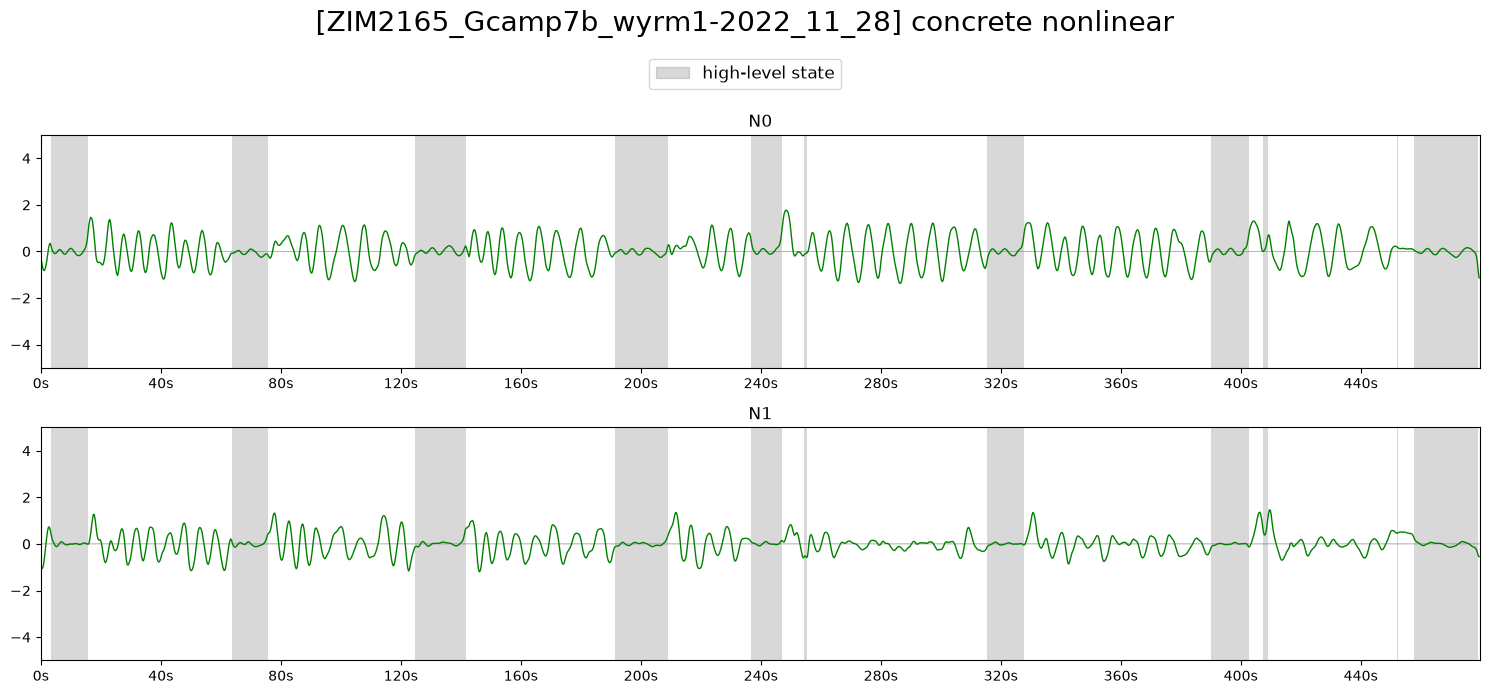

In [184]:
importlib.reload(plot_utils)
plot_utils.plot_traces(traces_concrete,
						# modulation_terms / np.max(modulation_terms.values, axis=0, keepdims=True) * np.max(traces_concrete.values, axis=0, keepdims=True)],
                        # modulation_terms],
					   discrete_states[['REV']],
					   timestamps,
					   label='high-level state',
					   title=f'[{filename}] concrete nonlinear', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
					   init_color='green',
					   save_path='../../out/plots/traces/concrete_nonlin' if save else None)

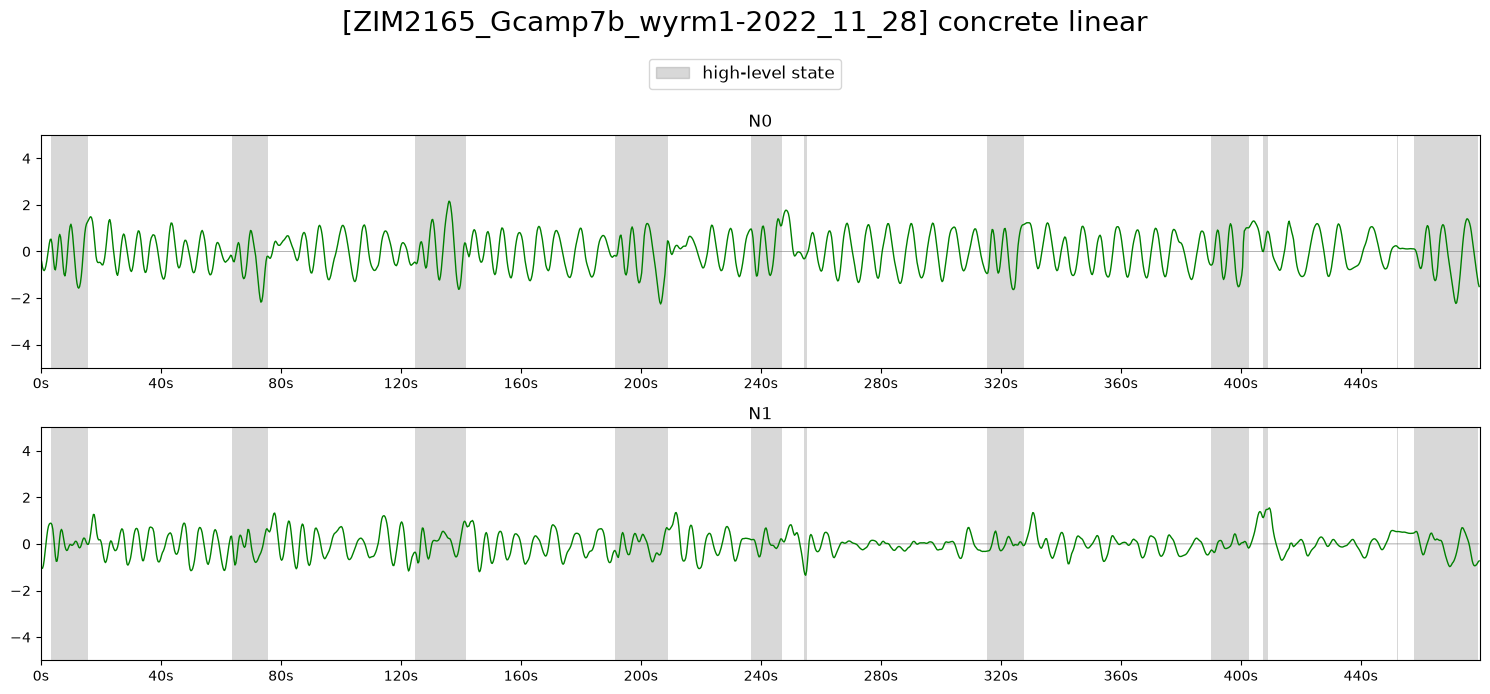

In [185]:
importlib.reload(analysis_utils)
(_, _, _, _, _,
 (_, _, _, modulation_terms_lin, traces_concrete_lin, _, params_lin, _)) = analysis_utils.read_data('robot', file_id, generate_data=((0.25, -1), neuron_labels, bhl_selection), model='bom')

importlib.reload(plot_utils)
plot_utils.plot_traces(traces_concrete_lin,
						# modulation_terms_lin / np.max(modulation_terms_lin.values, axis=0, keepdims=True) * np.max(traces_concrete_lin.values, axis=0, keepdims=True)],
					   discrete_states[['REV']],
					   timestamps,
					   label='high-level state',
					   title=f'[{filename}] concrete linear', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
					   init_color='green',
					   save_path='../../out/plots/traces/concrete_lin' if save else None)

In [186]:
# importlib.reload(plot_utils)
# plot_utils.plot_traces(traces_concrete_lin - traces_concrete,
# 					   discrete_states[['REV']],
# 					   timestamps,
# 					   label='high-level state',
# 					   title=f'[{filename}] concrete nonlinear vs linear difference', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
# 					   init_color='green',
# 					   save_path='../../out/plots/traces/concrete_nonlin_lin_diff' if save else None)

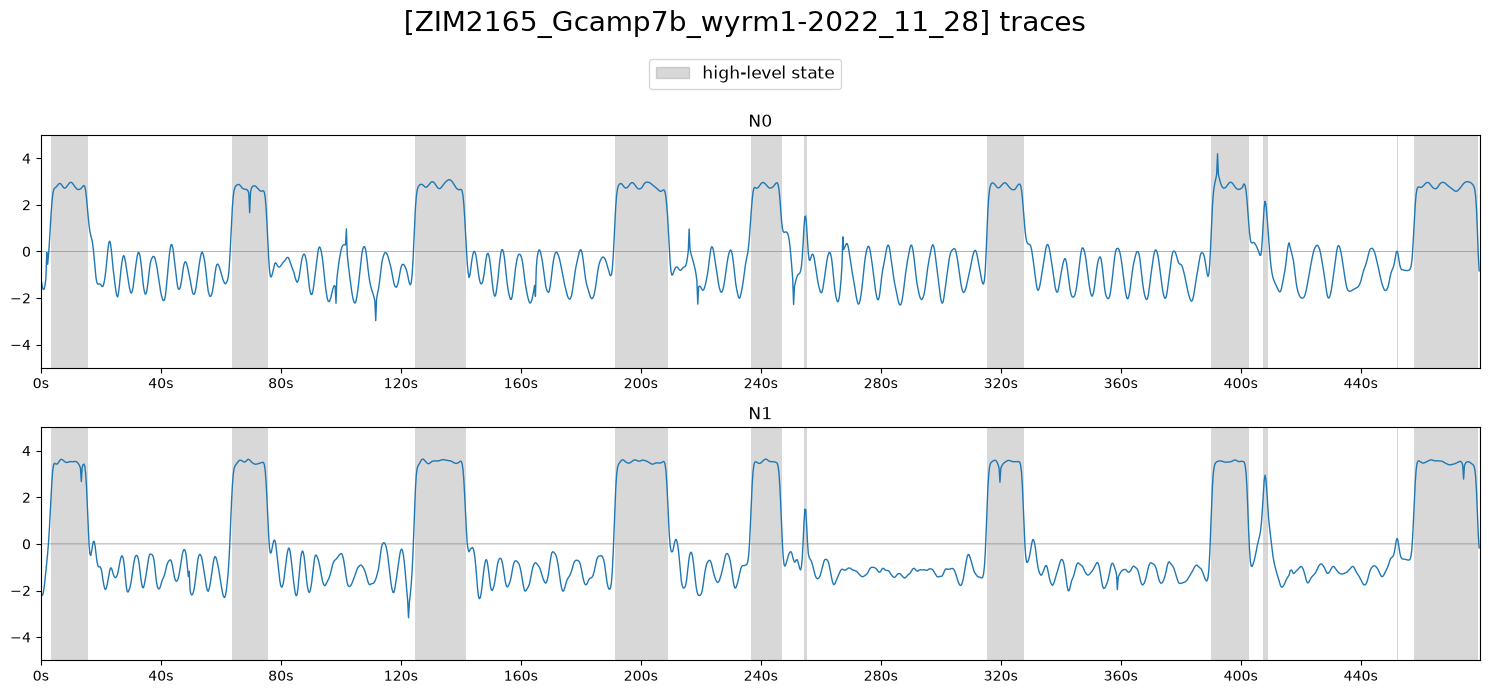

In [187]:
importlib.reload(plot_utils)
plot_utils.plot_traces(traces,
					   discrete_states[['REV']],
					   timestamps,
					   label='high-level state',
					   title=f'[{filename}] traces', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
					   init_color='C0',
					   save_path='../../out/plots/traces/traces' if save else None)

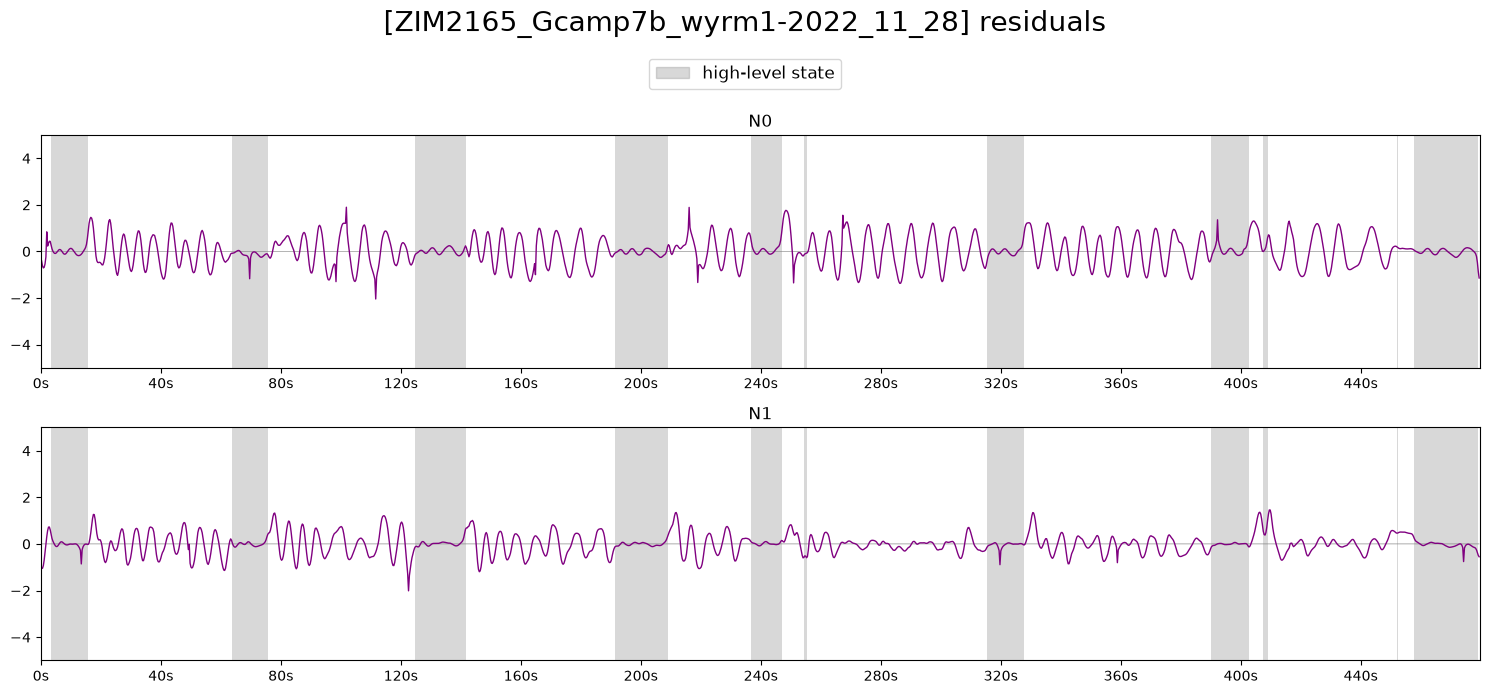

In [188]:
importlib.reload(plot_utils)
plot_utils.plot_traces(traces_residual,
					   discrete_states[['REV']],
					   timestamps,
					   label='high-level state',
					   title=f'[{filename}] residuals', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
					   init_color='purple',
					   save_path='../../out/plots/traces/residual' if save else None)

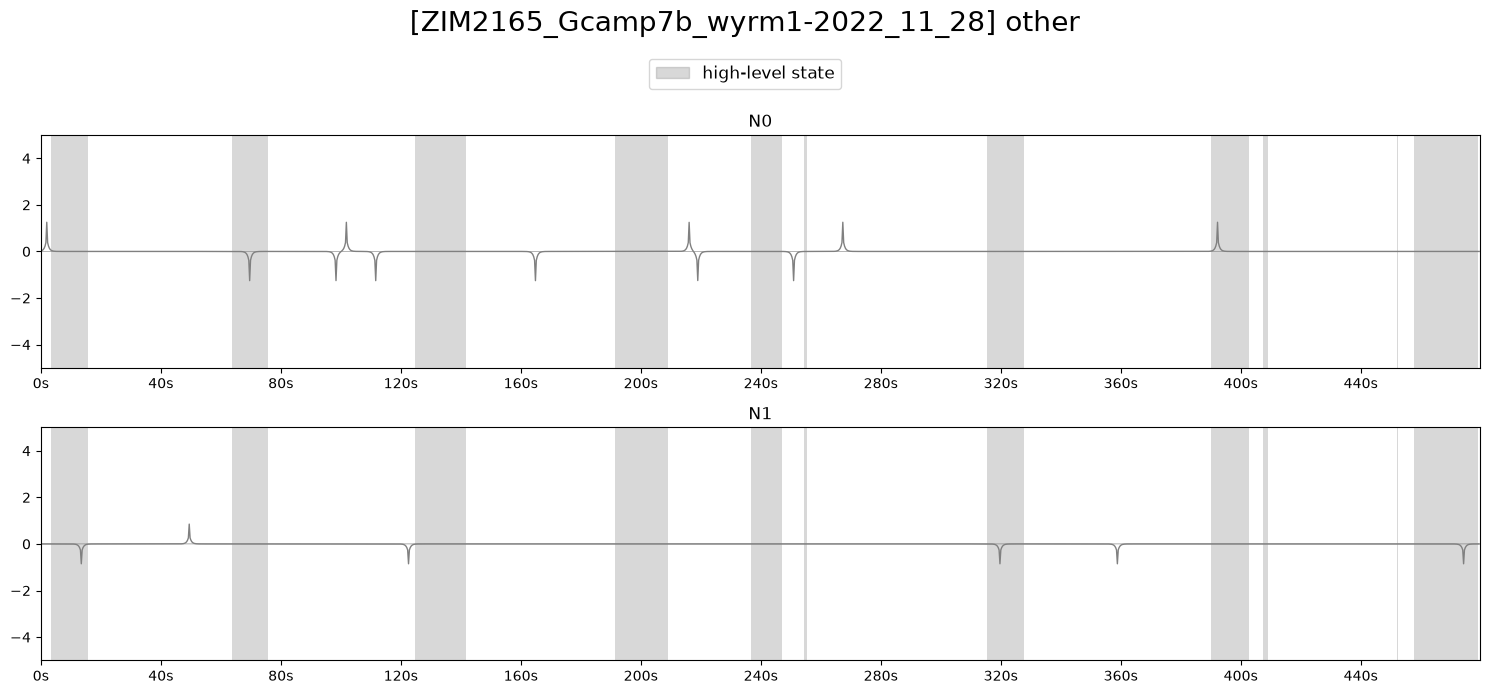

In [189]:
importlib.reload(plot_utils)
plot_utils.plot_traces(traces_other,
					   discrete_states[['REV']],
					   timestamps,
					   label='high-level state',
					   title=f'[{filename}] other', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
					   init_color='gray',
					   save_path='../../out/plots/traces/other' if save else None)

In [190]:
# importlib.reload(plot_utils)
# plot_utils.plot_traces([traces_concrete_lin,
# 						traces_concrete],
# 					   discrete_states[['REV']],
# 					   timestamps,
# 					   label='high-level state',
# 					   title=f'[{filename}] concrete nonlinear vs linear', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
# 					   init_color='green',
# 					   save_path='../../out/plots/traces/concrete_nonlin_lin' if save else None)

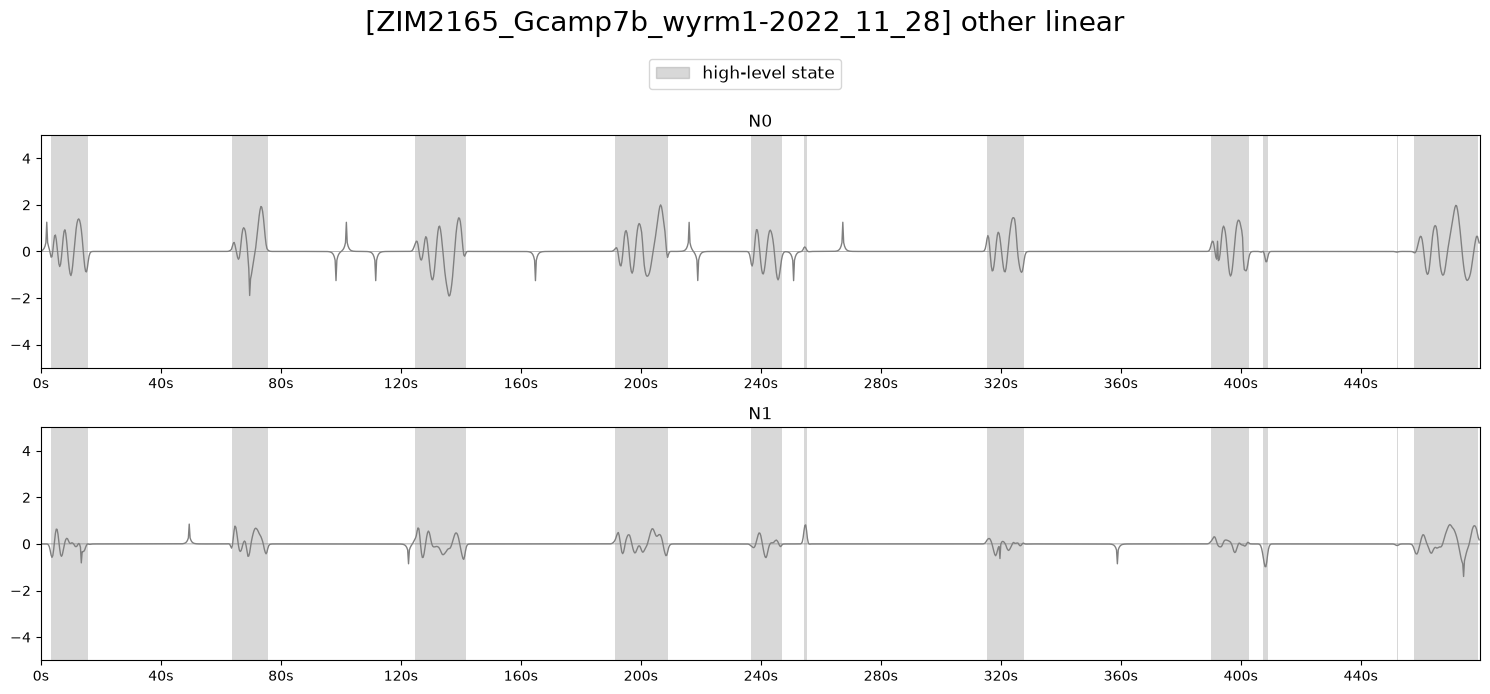

In [191]:
importlib.reload(plot_utils)
plot_utils.plot_traces(traces_residual - traces_concrete_lin,
					   discrete_states[['REV']],
					   timestamps,
					   label='high-level state',
					   title=f'[{filename}] other linear', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
					   init_color='gray',
					   save_path='../../out/plots/traces/other_lin' if save else None)

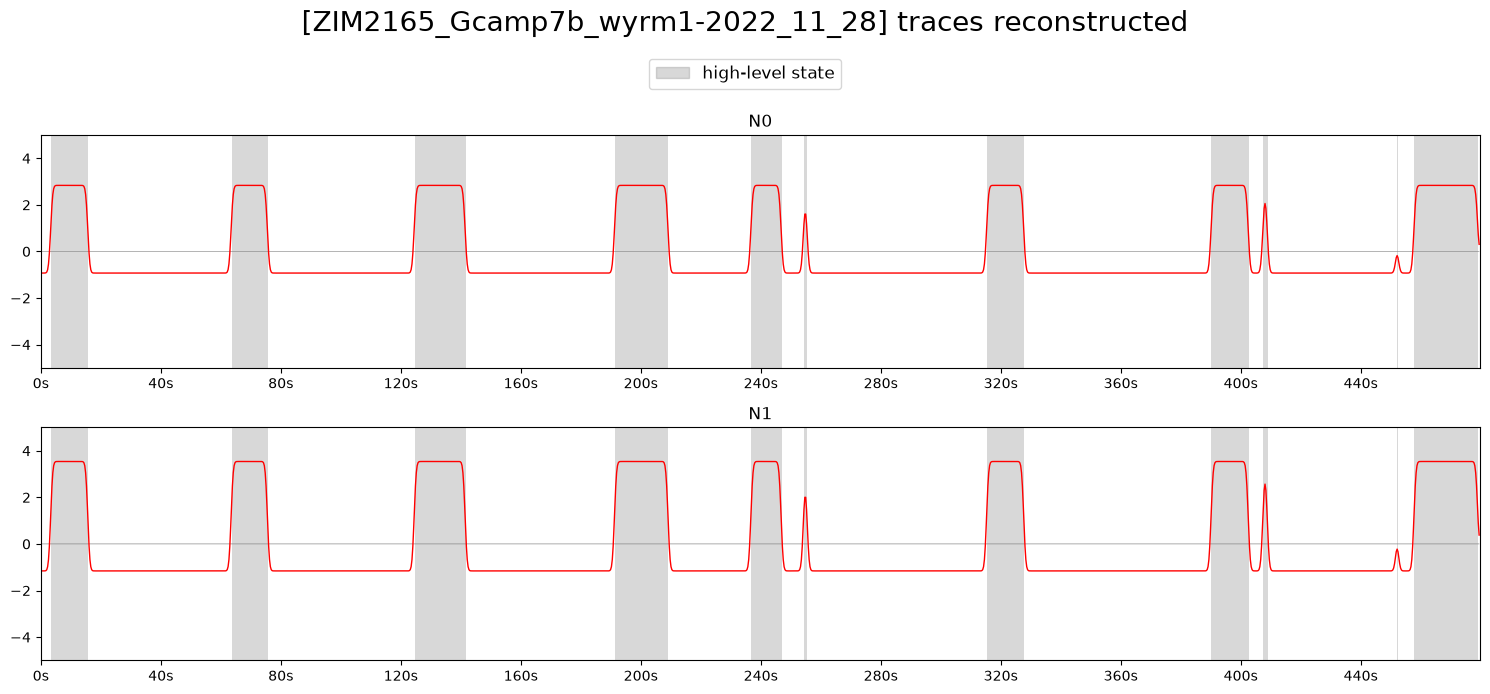

In [192]:
importlib.reload(plot_utils)
plot_utils.plot_traces(traces_reconstructed,
					   discrete_states[['REV']],
					   timestamps,
					   label='high-level state',
					   title=f'[{filename}] traces reconstructed', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
					   init_color='red',
					   save_path='../../out/plots/traces/traces_recon' if save else None)

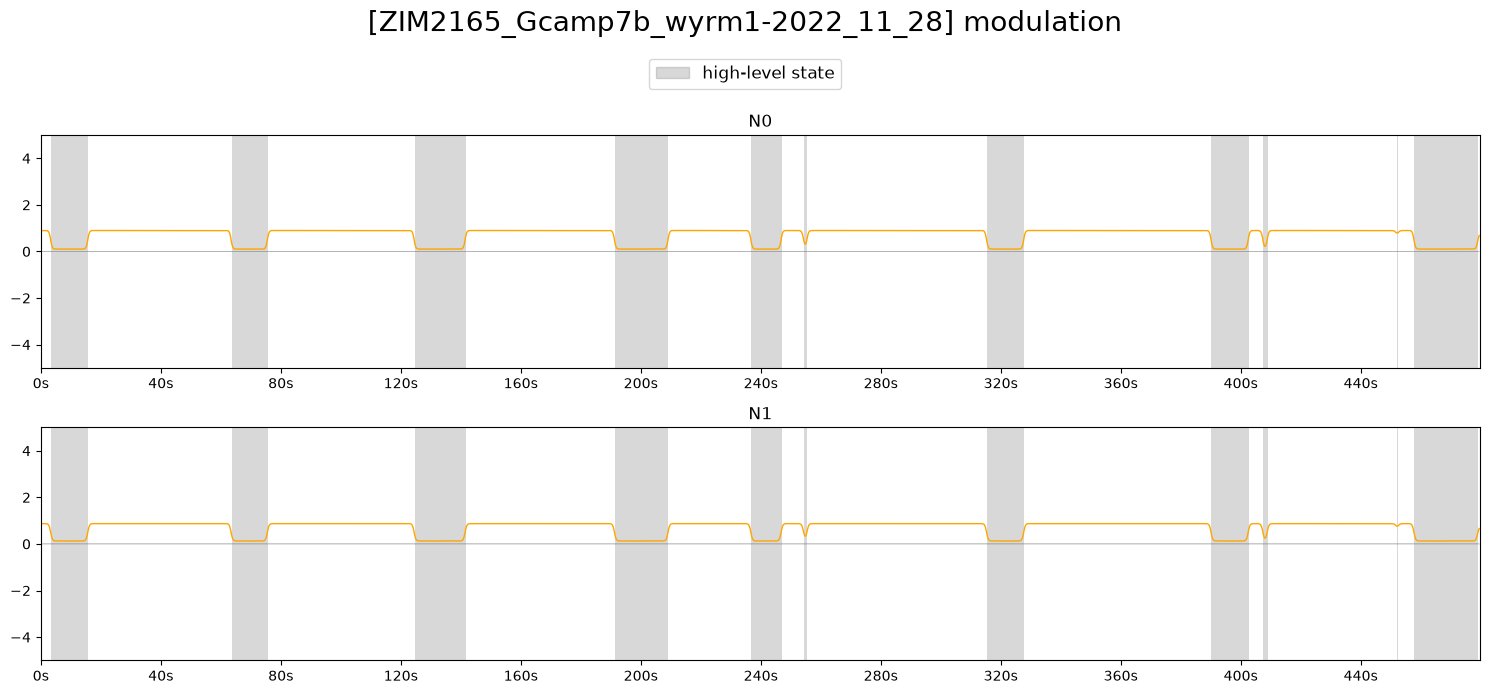

In [193]:
importlib.reload(plot_utils)
plot_utils.plot_traces(modulation_terms,
					   discrete_states[['REV']],
					   timestamps,
					   label='high-level state',
					   title=f'[{filename}] modulation', ylimits=(-5, 5), plots_per_row=1, n_plots=min(len(neuron_labels), 10),
					   init_color='orange',
					   save_path='../../out/plots/traces/modulation' if save else None)